# Credit Risk: Which Loans Should a Lender Approve?

A lender has 32,581 loan applications with the result of each loan (repaid or defaulted). The question is simple: **which applications should be approved to earn the most money?**

This notebook checks the data, finds what drives defaults, builds a model that predicts default, and then uses the model to choose an approval cut-off by looking at profit, not only accuracy.

**Terms used below**

- **Default:** the borrower does not repay the loan (`loan_status = 1`).
- **Default probability:** the model's estimate, from 0 to 1, that a loan will default.
- **Threshold:** a loan is approved only if its default probability is below this number.
- **AUC:** how well the model ranks risky loans above safe ones. 0.5 is a coin flip, 1.0 is perfect.
- **Precision and recall:** of the loans the model flags as defaults, how many really default (precision). Of all real defaults, how many the model catches (recall).
- **LGD (loss given default):** the share of the loan amount the lender loses when a loan defaults. Assumed to be 60%.

## 1.) Setup and Data

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# same colors in every chart: green = repaid, orange = default
GREEN, ORANGE, BLUE = sns.color_palette("Set2")[:3]
os.makedirs("../images", exist_ok=True)

In [2]:
df = pd.read_csv("../data/credit_risk.csv")
print(f"{len(df):,} loans, {df.shape[1]} columns")
print(f"Default rate: {df['loan_status'].mean():.1%}")
df.head(3)

32,581 loans, 29 columns
Default rate: 21.8%


,client_id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,gender,marital_status,education_level,country,state,city,city_latitude,city_longitude,employment_type,loan_term_months,loan_to_income_ratio,other_debt,debt_to_income_ratio,open_accounts,credit_utilization_ratio,past_delinquencies
0,CUST_00001,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,Male,Married,High School,Canada,Ontario,Toronto,43.6532,-79.3832,Self-employed,36,0.593220,8402.453850,0.735635,14,0.495557,0
1,CUST_00002,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2,Female,Divorced,Master,Canada,Ontario,Toronto,43.6532,-79.3832,Full-time,36,0.104167,1607.802794,0.271646,10,0.585436,3
2,CUST_00003,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3,Female,Married,Master,UK,Wales,Swansea,51.6214,-3.9436,Full-time,36,0.572917,2760.505633,0.860469,14,0.750732,0


The dataset comes from the DataDNA challenge (Onyx Data, September 2025). It looks like the well-known credit risk dataset with extra columns added later (gender, country, open accounts and others).

## 2.) Data Quality

In [3]:
missing = df.isna().sum()
print("Missing values:")
print(missing[missing > 0].to_string(), "\n")

print("Duplicate rows:", df.duplicated().sum())
print("Age above 100:", (df["person_age"] > 100).sum(), "(oldest:", df["person_age"].max(), ")")
print("Employment length above 60 years:", (df["person_emp_length"] > 60).sum(), "(longest:", df["person_emp_length"].max(), ")")
print("Income above $1M:", (df["person_income"] > 1_000_000).sum(), f"(highest: {df['person_income'].max():,})")

# other sanity checks: could the person really have worked or had credit that long?
print("Employment longer than (age - 14) years:", (df["person_emp_length"] > df["person_age"] - 14).sum())
print("Credit history longer than (age - 16) years:", (df["cb_person_cred_hist_length"] > df["person_age"] - 16).sum())

# is a missing employment length related to default?
emp_missing = df["person_emp_length"].isna()
print(f"\nDefault rate when employment length is missing: {df.loc[emp_missing, 'loan_status'].mean():.1%}")
print(f"Default rate when it is known: {df.loc[~emp_missing, 'loan_status'].mean():.1%}")

Missing values:
person_emp_length     895
loan_int_rate        3116 

Duplicate rows: 0
Age above 100: 5 (oldest: 144 )
Employment length above 60 years: 2 (longest: 123.0 )
Income above $1M: 9 (highest: 6,000,000)
Employment longer than (age - 14) years: 2
Credit history longer than (age - 16) years: 0

Default rate when employment length is missing: 31.5%
Default rate when it is known: 21.5%


**What I found and what I do about it**

- No duplicate rows.
- `person_emp_length` is missing for 895 loans and `loan_int_rate` for 3,116. Loans with a missing employment length default more often (31.5% vs 21.5%), so the missing value itself carries information. The model keeps a "was missing" flag for this reason.
- **7 rows have impossible values and are dropped.** 5 applicants have an age of 123 (2 loans) or 144 (3 loans), older than anyone who has ever lived (the record is 122). 2 applicants, aged 21 and 22, have 123 years of employment. Apart from those 2 rows nobody has worked since before age 14, and nobody has a credit history from before age 16, so the rest of the data holds up on these points.
- 9 incomes are above $1M. The highest ($6M) belongs to one of the 144-year-old applicants, so it is dropped with that row. The other 8 go up to $2.04M, which is unusual but possible, so they stay.

In [4]:
# drop the rows with impossible values, keep everything else
impossible = (df["person_age"] > 100) | (df["person_emp_length"] > 60)
df = df[~impossible].copy()
print(f"Dropped {impossible.sum()} rows, {len(df):,} left")

Dropped 7 rows, 32,574 left


## 3.) Columns That Do Not Help

In [5]:
groups = ["gender", "marital_status", "education_level", "country", "employment_type"]
rows = []
for col in groups:
    rate = df.groupby(col)["loan_status"].mean() * 100
    rows.append({"column": col, "groups": len(rate),
                 "lowest default rate (%)": rate.min(), "highest default rate (%)": rate.max()})
spread = pd.DataFrame(rows).set_index("column").round(1)
print(spread.to_string())

numbers = ["other_debt", "open_accounts", "credit_utilization_ratio", "past_delinquencies"]
print("\nCorrelation with default:")
print(df[numbers].corrwith(df["loan_status"]).round(3).to_string())

                 groups  lowest default rate (%)  highest default rate (%)
column                                                                    
gender                2                     21.8                      21.9
marital_status        4                     21.4                      22.0
education_level       4                     21.2                      22.2
country               3                     21.7                      21.9
employment_type       4                     21.6                      22.7

Correlation with default:
other_debt                 -0.135
open_accounts              -0.003
credit_utilization_ratio    0.007
past_delinquencies          0.000


**Observation:** the added columns do not separate good loans from bad ones. Default rates are almost the same in every group (for example 21.8% to 21.9% by gender and 21.7% to 21.9% by country), and the correlations of the number columns are close to zero. They are not used in the model. Gender, marital status and country are also not appropriate to use in a lending decision, so there is no reason to keep them.

## 4.) What Drives Default

            loans  default_rate
loan_grade                     
A           10776          10.0
B           10448          16.3
C            6456          20.7
D            3625          59.0
E             964          64.4
F             241          70.5
G              64          98.4


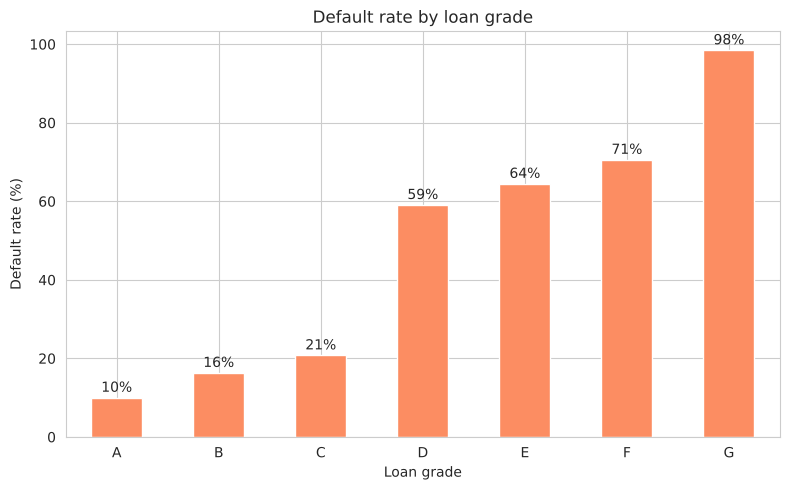

In [6]:
by_grade = df.groupby("loan_grade")["loan_status"].agg(loans="size", default_rate="mean")
by_grade["default_rate"] = by_grade["default_rate"] * 100
print(by_grade.round(1).to_string())

ax = by_grade["default_rate"].plot(kind="bar", color=ORANGE, figsize=(8, 5))
ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=2)
plt.title("Default rate by loan grade")
plt.xlabel("Loan grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/default_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** default rates climb with the grade, from 10.0% for grade A to 98.4% for grade G. The big jump is between C (20.7%) and D (59.0%). The grade is set by the lender after looking at the risk, so it cannot be used to predict default (see section 5).

Home ownership
person_home_ownership
RENT        31.6
OTHER       30.8
MORTGAGE    12.6
OWN          7.5 

Defaulted before
cb_person_default_on_file
Y    37.8
N    18.4 

Loan purpose
loan_intent
DEBTCONSOLIDATION    28.6
MEDICAL              26.7
HOMEIMPROVEMENT      26.1
PERSONAL             19.9
EDUCATION            17.2
VENTURE              14.8 



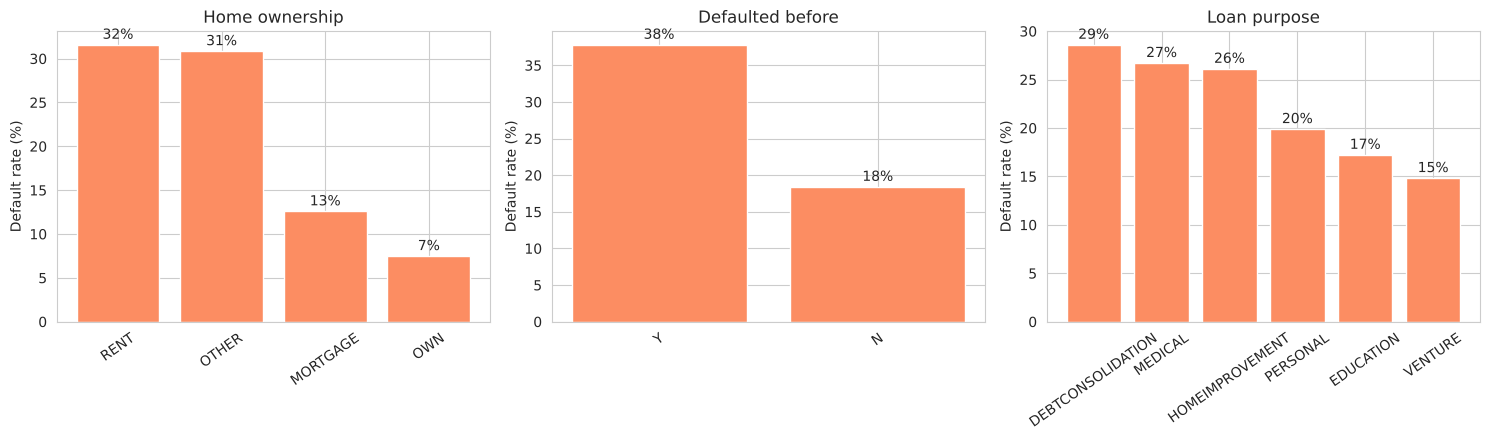

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
panels = [("person_home_ownership", "Home ownership"),
          ("cb_person_default_on_file", "Defaulted before"),
          ("loan_intent", "Loan purpose")]

for ax, (col, title) in zip(axes, panels):
    rate = df.groupby(col)["loan_status"].mean().mul(100).sort_values(ascending=False)
    print(title)
    print(rate.round(1).to_string(), "\n")
    ax.bar(rate.index, rate.values, color=ORANGE)
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=2)
    ax.set_title(title)
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig("../images/default_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

Loan amount as share of income
            loans  default_rate
loan_share                     
up to 10%   10472          11.7
10-20%      12066          15.1
20-30%       6195          22.0
over 30%     3833          70.3 

Income group
                 loans  default_rate
income_quartile                     
Q1 (lowest)       8152          39.7
Q2                8231          21.3
Q3                8053          17.1
Q4 (highest)      8138           9.1 



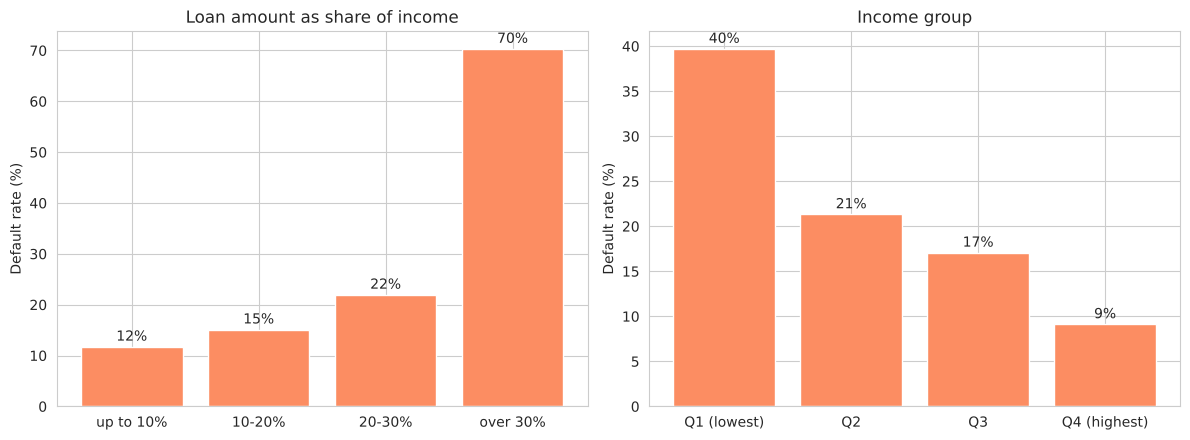

In [8]:
df["loan_share"] = pd.cut(df["loan_percent_income"], [0, 0.1, 0.2, 0.3, 1.0],
                          labels=["up to 10%", "10-20%", "20-30%", "over 30%"])
df["income_quartile"] = pd.qcut(df["person_income"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (col, title) in zip(axes, [("loan_share", "Loan amount as share of income"),
                                   ("income_quartile", "Income group")]):
    table = df.groupby(col, observed=True)["loan_status"].agg(loans="size", default_rate="mean")
    table["default_rate"] = table["default_rate"] * 100
    print(title)
    print(table.round(1).to_string(), "\n")
    ax.bar(table.index.astype(str), table["default_rate"], color=ORANGE)
    ax.bar_label(ax.containers[0], fmt="%.0f%%", padding=2)
    ax.set_title(title)
    ax.set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../images/default_by_share_and_income.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation**

- **Renting** (31.6%) is four times riskier than owning (7.5%), and a **previous default** doubles the risk (37.8% vs 18.4%).
- **Debt consolidation** (28.6%) and medical loans (26.7%) default more than venture (14.8%) or education loans (17.2%).
- **The size of the loan compared with income** matters most: above 30% of income, 70.3% of loans default (11.7% when it is under 10%).
- **Lower income** means higher risk: 39.7% in the lowest income group vs 9.1% in the highest.
- Loan term (20% to 22% for every term) and age (20% to 23% for every age group) make almost no difference.

## 5.) Prediction Model

**Which columns go into the model**

The model should only use what the lender knows when the application arrives. I use: age, income, employment length, loan amount, loan amount as share of income, credit history length, loan term, home ownership, loan purpose and previous default.

**Left out on purpose**

- `loan_grade` and `loan_int_rate`: the lender sets these after judging the risk, so using them is a form of leakage. The section below shows how much they would inflate the result.
- The added columns (gender, marital status, education, country, employment type, other debt and so on): no signal, and some should not be used in lending.

I compare two models: logistic regression (simple, easy to explain) and gradient boosting (finds more complex patterns). The test set is 25% of the loans, split with the same default rate as the rest.

In [9]:
numeric = ["person_age", "person_income", "person_emp_length", "loan_amnt",
           "loan_percent_income", "cb_person_cred_hist_length", "loan_term_months"]
categorical = ["person_home_ownership", "loan_intent", "cb_person_default_on_file"]

X = df[numeric + categorical]
y = df["loan_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"{len(X_train):,} training loans, {len(X_test):,} test loans")


def build(model, num, cat, scale):
    # fill missing numbers with the median and keep a "was missing" flag
    steps = [("fill", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        steps.append(("scale", StandardScaler()))
    prep = ColumnTransformer([
        ("num", Pipeline(steps), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    return Pipeline([("prep", prep), ("model", model)])


logistic = build(LogisticRegression(max_iter=1000), numeric, categorical, scale=True)
boosting = build(HistGradientBoostingClassifier(random_state=0), numeric, categorical, scale=False)
logistic.fit(X_train, y_train)
boosting.fit(X_train, y_train)

24,430 training loans, 8,144 test loans


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['person_age','person_income','person_emp_length',..., 'person_home_ownership','loan_intent','cb_person_default_on_file']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, model in [("Logistic regression", logistic), ("Gradient boosting", boosting)]:
    p = model.predict_proba(X_test)[:, 1]
    flagged = (p >= 0.5).astype(int)
    rows.append({
        "model": name,
        "AUC (test)": roc_auc_score(y_test, p),
        "AUC (5-fold CV)": cross_val_score(model, X, y, cv=cv, scoring="roc_auc").mean(),
        "precision at 0.5": precision_score(y_test, flagged),
        "recall at 0.5": recall_score(y_test, flagged),
    })
results = pd.DataFrame(rows).set_index("model").round(3)
results

,AUC (test),AUC (5-fold CV),precision at 0.5,recall at 0.5
model,,,,
Logistic regression,0.797,0.805,0.726,0.387
Gradient boosting,0.891,0.900,0.920,0.533


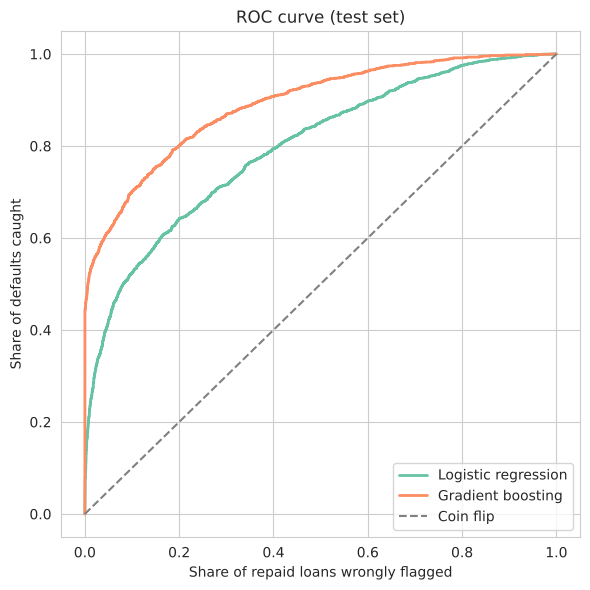

In [11]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, model, color in [("Logistic regression", logistic, GREEN), ("Gradient boosting", boosting, ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=name)
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Coin flip")
ax.set_xlabel("Share of repaid loans wrongly flagged")
ax.set_ylabel("Share of defaults caught")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** gradient boosting is clearly better (AUC 0.891 vs 0.797 on the test set, and 0.900 vs 0.805 in cross-validation, so the result is stable). At the usual cut-off of 0.5 it is also precise: 92% of the loans it flags really default, but it only catches 53% of all defaults. That cut-off is not necessarily the best one for a lender, which is why section 6 looks at profit.

             loans  predicted  actual
risk_band                            
1 (lowest)    1629        1.9     1.5
2             1629        5.3     5.0
3             1628        9.9     9.6
4             1629       20.5    21.7
5 (highest)   1629       70.8    71.3


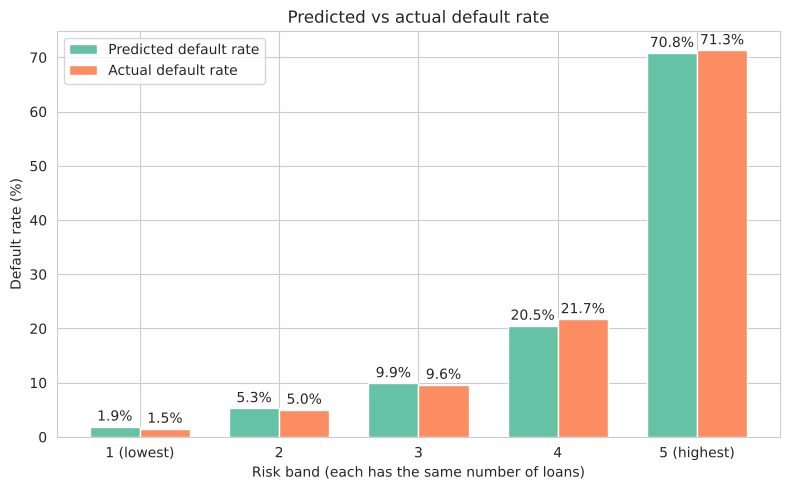

In [12]:
# are the predicted probabilities honest? group the test loans into 5 equal risk bands
test = df.loc[X_test.index].copy()
test["p_default"] = boosting.predict_proba(X_test)[:, 1]
test["risk_band"] = pd.qcut(test["p_default"].rank(method="first"), 5,
                            labels=["1 (lowest)", "2", "3", "4", "5 (highest)"])

bands = test.groupby("risk_band", observed=True).agg(
    loans=("p_default", "size"),
    predicted=("p_default", "mean"),
    actual=("loan_status", "mean"))
bands[["predicted", "actual"]] = (bands[["predicted", "actual"]] * 100).round(1)
print(bands.to_string())

x = np.arange(len(bands))
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - 0.18, bands["predicted"], 0.36, color=GREEN, label="Predicted default rate")
b2 = ax.bar(x + 0.18, bands["actual"], 0.36, color=ORANGE, label="Actual default rate")
ax.bar_label(b1, fmt="%.1f%%", padding=2)
ax.bar_label(b2, fmt="%.1f%%", padding=2)
ax.set_xticks(x)
ax.set_xticklabels(bands.index)
ax.set_xlabel("Risk band (each has the same number of loans)")
ax.set_ylabel("Default rate (%)")
ax.set_title("Predicted vs actual default rate")
ax.legend()
plt.tight_layout()
plt.savefig("../images/risk_bands.png", dpi=150, bbox_inches="tight")
plt.show()

**Observation:** the predictions are close to what really happened in every band (for example 5.3% predicted and 5.0% actual in band 2, 70.8% and 71.3% in the riskiest band). This matters because the profit calculation below uses the probabilities themselves, not only the ranking.

person_income                 0.120
loan_percent_income           0.087
person_home_ownership         0.081
loan_intent                   0.051
cb_person_default_on_file     0.031
loan_amnt                     0.018
person_emp_length             0.008
person_age                    0.007
cb_person_cred_hist_length   -0.000
loan_term_months             -0.000


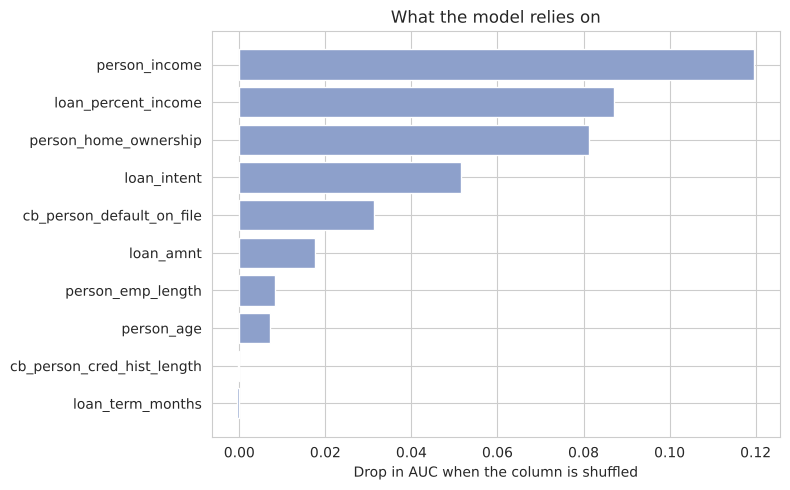

In [13]:
# which columns matter most? shuffle one column at a time and see how much AUC drops
imp = permutation_importance(boosting, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=0)
importance = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
print(importance.round(3).sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=BLUE)
ax.set_xlabel("Drop in AUC when the column is shuffled")
ax.set_title("What the model relies on")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# how much would leakage and the added columns change the result? (same model, different columns)
def test_auc(num, cat):
    X2 = df[num + cat]
    a, b, c, d = train_test_split(X2, y, test_size=0.25, random_state=42, stratify=y)
    model = build(HistGradientBoostingClassifier(random_state=0), num, cat, scale=False).fit(a, c)
    return roc_auc_score(d, model.predict_proba(b)[:, 1])


added_num = ["other_debt", "debt_to_income_ratio", "open_accounts", "credit_utilization_ratio", "past_delinquencies"]
added_cat = ["gender", "marital_status", "education_level", "country", "employment_type"]

checks = pd.Series({
    "Application data only (used in the model)": test_auc(numeric, categorical),
    "+ loan_grade and loan_int_rate (leakage)": test_auc(numeric + ["loan_int_rate"], categorical + ["loan_grade"]),
    "+ the added columns (gender, country, debt...)": test_auc(numeric + added_num, categorical + added_cat),
}).round(3)
checks.to_frame("AUC (test)")

,AUC (test)
Application data only (used in the model),0.891
+ loan_grade and loan_int_rate (leakage),0.937
"+ the added columns (gender, country, debt...)",0.885


**Observation:** adding the loan grade and interest rate lifts the AUC from 0.891 to 0.937, which looks like a better model but is not real: the lender picks them after judging the risk. Adding the extra columns does not help at all (0.885, slightly lower). That supports leaving both out.

## 6.) Business Evaluation: Where to Set the Cut-off

A model score only becomes a decision once we pick a threshold. A loan is approved when its default probability is below the threshold. A low threshold approves fewer loans (safer, but we lose good customers). A high threshold approves more (more interest, but more losses).

**Assumptions (change them and run again)**

- A repaid loan earns the interest of the whole loan, with standard monthly payments.
- A defaulted loan loses 60% of the loan amount (LGD = 60%). The table below also tries 40% and 80%.
- A rejected loan earns and loses nothing.
- Missing interest rates use the median rate.
- Costs of running the business are ignored. These are results on the 8,144 test loans, for comparing choices, not a forecast.

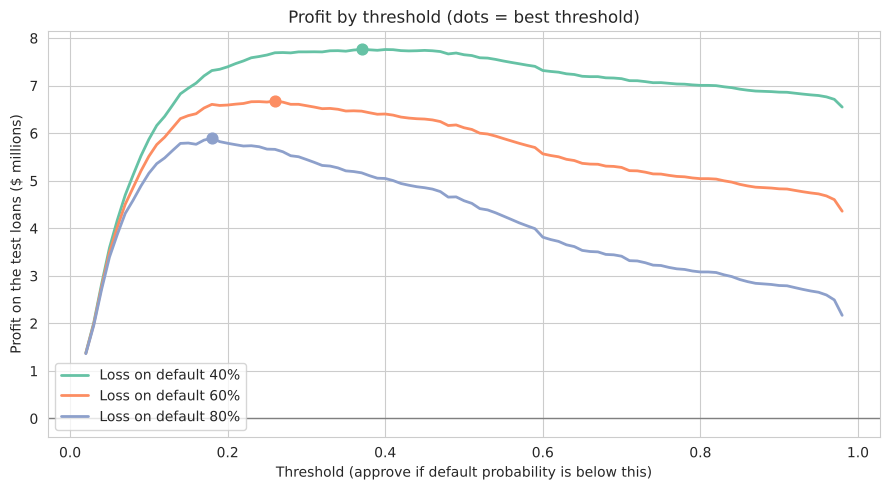

In [15]:
# interest earned over the whole loan if it is repaid (standard monthly payments)
rate = test["loan_int_rate"].fillna(df["loan_int_rate"].median())
monthly = rate / 1200
months = test["loan_term_months"]
payment = test["loan_amnt"] * monthly / (1 - (1 + monthly) ** (-months))
test["interest"] = months * payment - test["loan_amnt"]


def profit(approved, lgd=0.60):
    repaid = test["loan_status"] == 0
    result = test["interest"].where(repaid, -lgd * test["loan_amnt"])
    return result[approved].sum()


thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
best = {}
for lgd in [0.4, 0.6, 0.8]:
    curve = [profit(test["p_default"] < t, lgd) for t in thresholds]
    i = int(np.argmax(curve))
    best[lgd] = (thresholds[i], curve[i])

fig, ax = plt.subplots(figsize=(9, 5))
for lgd, color in [(0.4, GREEN), (0.6, ORANGE), (0.8, BLUE)]:
    curve = [profit(test["p_default"] < t, lgd) / 1e6 for t in thresholds]
    ax.plot(thresholds, curve, color=color, linewidth=2, label=f"Loss on default {lgd:.0%}")
    ax.scatter(best[lgd][0], best[lgd][1] / 1e6, color=color, s=60, zorder=3)
ax.axhline(0, color="grey", linewidth=1)
ax.set_xlabel("Threshold (approve if default probability is below this)")
ax.set_ylabel("Profit on the test loans ($ millions)")
ax.set_title("Profit by threshold (dots = best threshold)")
ax.legend()
plt.tight_layout()
plt.savefig("../images/profit_by_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
def summary(label, approved, lgd=0.60):
    return {"strategy": label,
            "approval rate": approved.mean(),
            "default rate of approved loans": test.loc[approved, "loan_status"].mean(),
            "profit ($)": profit(approved, lgd)}


t_best = best[0.6][0]
strategies = pd.DataFrame([
    summary("Approve every loan", test["p_default"] < 2),
    summary("Model, threshold 0.50", test["p_default"] < 0.5),
    summary(f"Model, best threshold {t_best:.2f}", test["p_default"] < t_best),
]).set_index("strategy")
strategies["approval rate"] = (strategies["approval rate"] * 100).round(1)
strategies["default rate of approved loans"] = (strategies["default rate of approved loans"] * 100).round(1)
strategies["profit ($)"] = strategies["profit ($)"].round(0)
print("Loss on default = 60%")
print(strategies.to_string())

rows = []
for lgd, (t, p) in best.items():
    approved = test["p_default"] < t
    rows.append({"loss on default": f"{lgd:.0%}", "best threshold": t,
                 "approval rate (%)": round(approved.mean() * 100, 1),
                 "default rate of approved (%)": round(test.loc[approved, "loan_status"].mean() * 100, 1),
                 "profit with model ($)": round(p),
                 "profit approving all ($)": round(profit(test["p_default"] < 2, lgd))})
print("\nHow the answer changes with the loss assumption")
print(pd.DataFrame(rows).set_index("loss on default").to_string())

Loss on default = 60%
                            approval rate  default rate of approved loans  profit ($)
strategy                                                                             
Approve every loan                  100.0                            21.8   -721115.0
Model, threshold 0.50                87.4                            11.7   6115590.0
Model, best threshold 0.26           76.5                             8.4   6676607.0

How the answer changes with the loss assumption
                 best threshold  approval rate (%)  default rate of approved (%)  profit with model ($)  profit approving all ($)
loss on default                                                                                                                  
40%                        0.37               83.2                          10.3                7761875                   3162965
60%                        0.26               76.5                           8.4                6676607      

**Observation (loss on default = 60%)**

- Approving every loan loses money (about -$0.72M on the test loans), because the 21.8% of loans that default cost more than the interest the other loans pay.
- The model at the usual 0.50 cut-off already turns this into a profit of about $6.12M.
- Choosing the cut-off with profit in mind (0.26) adds about $0.56M more (+9%). It approves 76.5% of loans, and only 8.4% of the approved loans default (vs 21.8% overall).
- The best threshold depends on how much a default costs: 0.37 when 40% of the loan is lost, 0.26 at 60%, and 0.18 at 80%. The higher the loss, the stricter the lender should be. So the real cost of a default is the number to get from the finance team first.

## 7.) Fairness Check

In [17]:
# the model does not use these columns, but are approval rates still similar across groups?
approved = test["p_default"] < t_best
test["approved"] = approved

tables = []
for col in ["gender", "marital_status", "education_level", "country", "employment_type"]:
    g = test.groupby(col).agg(loans=("approved", "size"), approval_rate=("approved", "mean"),
                              default_rate=("loan_status", "mean"))
    g[["approval_rate", "default_rate"]] = (g[["approval_rate", "default_rate"]] * 100).round(1)
    g.index = [f"{col}: {i}" for i in g.index]
    tables.append(g)
pd.concat(tables)

,loans,approval_rate,default_rate
gender: Female,4071,77.0,21.3
gender: Male,4073,76.0,22.3
marital_status: Divorced,797,75.4,22.5
marital_status: Married,2806,77.5,21.8
marital_status: Single,4141,76.4,21.9
marital_status: Widowed,400,73.5,19.8
education_level: Bachelor,2840,76.0,22.1
education_level: High School,3311,75.2,21.9
education_level: Master,1626,79.5,21.1
education_level: PhD,367,79.3,21.8


**Observation:** approval rates are close for gender (77.0% for women and 76.0% for men) and country (75.4% to 77.6%). The widest gap is by education: 79.5% for Master and 79.3% for PhD against 75.2% for High School. The model never sees these columns, and education has no link to income or loan size in this data, so the gap is most likely chance (the groups are small), but it is the first thing to check on real customers. Widowed applicants (73.5%) also have a lower approval rate than married ones (77.5%), with only 400 loans in the group.

## 8.) Recommendations and Limitations

**Recommendations**

1. **Use the model, but choose the cut-off from profit.** Approving everything loses money. The model turns that into a profit, and a profit-based cut-off adds about 9% more than the default 0.50.
2. **Get the real cost of a default** (loss given default) before fixing the threshold. It moves the best cut-off from 0.37 to 0.18.
3. **Look closely at loans that are above 30% of income, rent-based applicants and applicants with a previous default.** These are the groups with the highest default rates (70.3%, 31.6% and 37.8%).
4. **Do not use the lender's own grade or interest rate as model inputs,** and do not use gender, marital status or country.

**Limitations**

- The extra columns look simulated (no link to default), and the loan results come from a public-style dataset, so real results will differ.
- The profit numbers rest on assumptions (LGD, interest earned over the full term, no costs, a loan defaulting at the start). They are good for comparing choices, not for forecasting.
- The test set is one random split of 8,144 loans. The cross-validation result (0.900) shows the model is stable, but there is no check on new time periods.
- A missing employment length is treated as information. If the data collection changes, this flag could stop working.